# Module 11: Weighing the water under the Snake River Plain

*The code behind GEOS 212: Water in the West, Boise State University*

How do you measure how much water is stored underground across a whole region? Wells tell you the water level at one spot. But since 2002, a pair of satellites has been doing something remarkable: **weighing** the water.

The **GRACE** mission (Gravity Recovery and Climate Experiment, 2002-2017) and its successor **GRACE-FO** (Follow-On, 2018-today) are pairs of satellites flying about 220 km apart, one behind the other. When the lead satellite passes over a region with extra mass, like a big snowpack or a full aquifer, gravity pulls it ahead slightly, and the distance between the pair changes by a few micrometers (less than the width of a hair). Measuring that distance with microwaves, month after month, lets scientists map how Earth's gravity, and therefore its water, changes.

What GRACE measures is **total water storage (TWS)**: snow + soil moisture + groundwater + reservoirs + rivers, all added together, expressed as a thickness of water (cm) spread over the area.

**Where are we in the water year?** In the *groundwater*: the slowest, deepest storage in the Boise River basin and the Snake River Plain.

> **New to Jupyter?** Click a gray code cell and press **Shift + Enter** to run it. Run the cells in order.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

INK, DEEP, RIVER, GLACIER, OCHRE, BASALT, MIST = (
    "#14303F", "#0E4D64", "#137C8B", "#4FB0C6", "#D9822B", "#5B6770", "#EAF4F4")
plt.rcParams.update({"figure.dpi": 110, "font.size": 12,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = Path("../data")
DATA_URL = "https://raw.githubusercontent.com/LejoFlores/geos212-code/main/data/"

## 2. Loading the data

Downloading GRACE data requires a free NASA Earthdata account, so we saved a summary: the average total water storage over a box around the Snake River Plain (42.5-44.5° N, 111-116° W), every month from April 2002 to July 2026. Values are **anomalies**: the difference from the 2004-2009 average, in centimeters of water.

GRACE is blurry: its "pixels" (called *mascons*) are about 300 km across. So our box is a regional average that includes the mountain snowpack around the plain, not just the aquifer.

In [2]:
name = "grace_snake_plain_tws.csv"
source = DATA_DIR / name if (DATA_DIR / name).exists() else DATA_URL + name
tws = pd.read_csv(source, parse_dates=["time"], index_col="time")["tws_cm"]
print(f"{len(tws)} monthly values, {tws.index.min():%b %Y} to {tws.index.max():%b %Y}")
tws.head()

259 monthly values, Apr 2002 to Jul 2026


time
2002-04-17 12:00:00     8.41
2002-05-10 12:00:00     6.73
2002-08-16 12:00:00    -9.89
2002-09-16 00:00:00   -11.29
2002-10-16 12:00:00   -13.06
Name: tws_cm, dtype: float64

## 3. The whole record

Let's plot every month. We'll also compute a **12-month running mean** (the average of the surrounding 12 months), which smooths out the seasons so we can see the slower changes. Notice the gap from mid-2017 to mid-2018: the first GRACE mission ended before GRACE-FO launched.

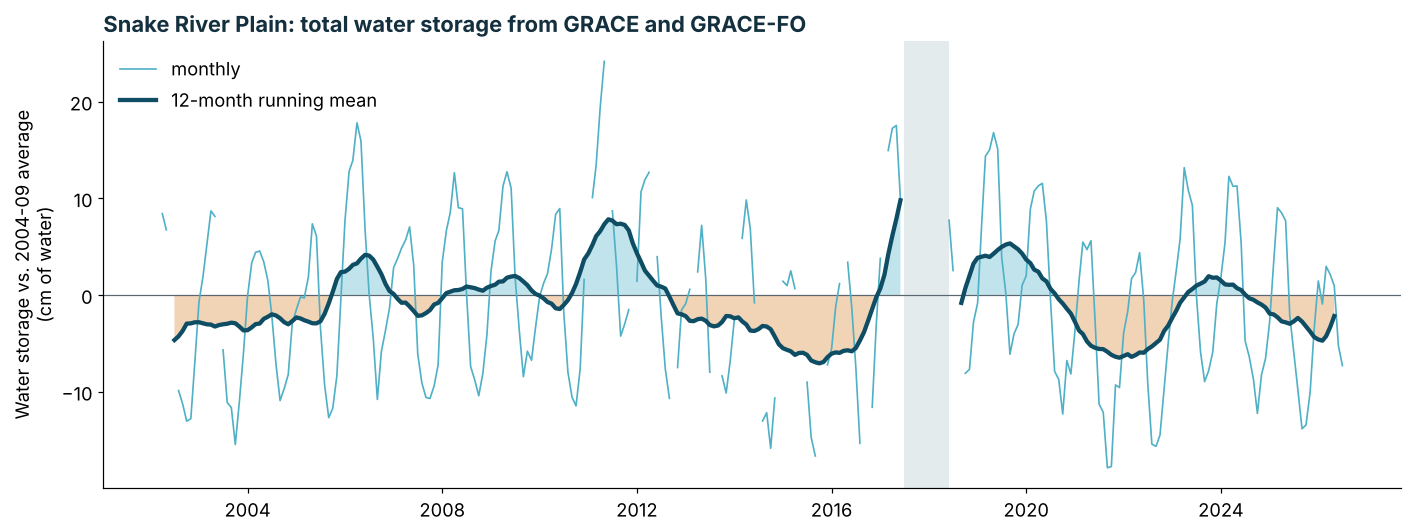

In [3]:
monthly = tws.resample("MS").mean()                       # one value per calendar month (gaps stay empty)
smooth = monthly.interpolate(limit=3).rolling(12, center=True, min_periods=9).mean()
smooth["2017-07":"2018-05"] = np.nan                      # don't draw across the mission gap

fig, ax = plt.subplots(figsize=(13, 5))
ax.axhline(0, color=BASALT, lw=0.8)
ax.plot(monthly.index, monthly, color=GLACIER, lw=1.1, label="monthly")
ax.fill_between(smooth.index, 0, smooth, where=smooth >= 0, color=GLACIER, alpha=0.35, lw=0, interpolate=True)
ax.fill_between(smooth.index, 0, smooth, where=smooth < 0, color=OCHRE, alpha=0.35, lw=0, interpolate=True)
ax.plot(smooth.index, smooth, color=DEEP, lw=2.8, label="12-month running mean")
ax.axvspan(pd.Timestamp("2017-07-01"), pd.Timestamp("2018-05-31"), color="#E3EBEC", lw=0)
ax.set_ylabel("Water storage vs. 2004-09 average\n(cm of water)")
ax.set_title("Snake River Plain: total water storage from GRACE and GRACE-FO", loc="left", fontweight="bold", color=INK)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()

## 4. Taking it apart: seasons vs. years

The thin line has a big up-and-down every year. Let's average all the Januaries, all the Februaries, and so on to get the typical **seasonal cycle**.

Seasonal swing, wettest month to driest: 20 cm of water


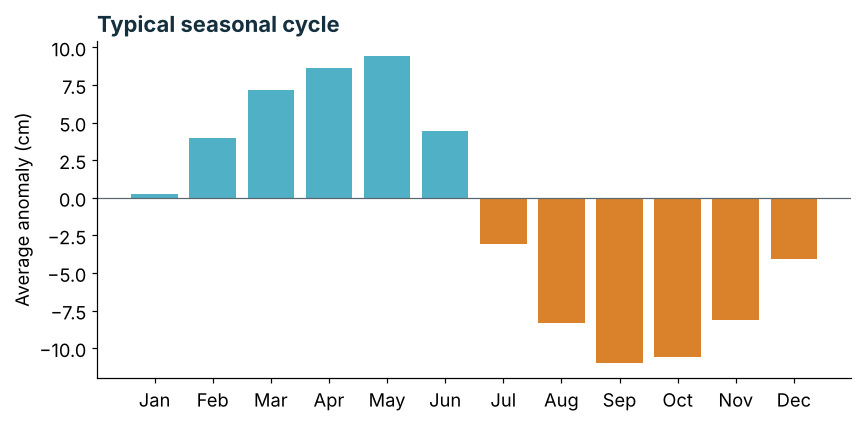

In [4]:
seasonal = tws.groupby(tws.index.month).mean()
names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(names, seasonal, color=[GLACIER if v >= 0 else OCHRE for v in seasonal])
ax.axhline(0, color=BASALT, lw=0.8)
ax.set_ylabel("Average anomaly (cm)")
ax.set_title("Typical seasonal cycle", loc="left", fontweight="bold", color=INK)
plt.tight_layout()
print(f"Seasonal swing, wettest month to driest: {seasonal.max() - seasonal.min():.0f} cm of water")

Storage peaks in spring and bottoms out in early fall. What fills it up every winter and drains it every summer? Mostly the **snowpack** (Modules 04-06), plus soil moisture and reservoirs. Then, through the summer, snowmelt runs off, crops use water, and irrigators pump groundwater.

Now the year-to-year changes, using annual means:

time
2003   -3.4
2004   -2.0
2005   -2.7
2006    4.1
2007   -2.2
2008    0.9
2009    2.0
2010   -1.0
2011    7.8
2012    1.1
2013   -2.5
2014   -3.6
2015   -4.6
2016   -4.6
2019    5.0
2020    0.6
2021   -5.6
2022   -5.6
2023    1.0
2024    0.0
2025   -2.7


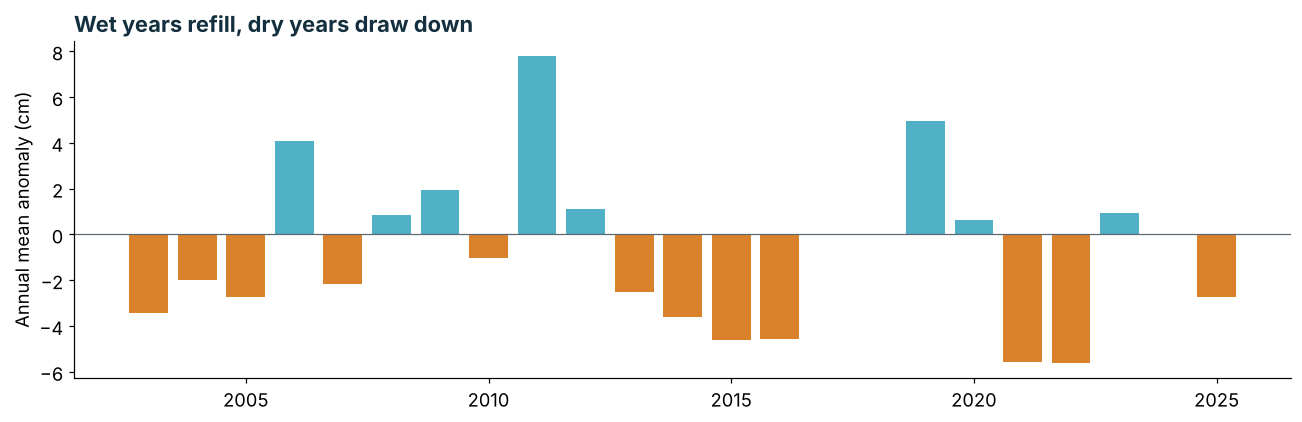

In [5]:
annual = tws.groupby(tws.index.year).agg(["mean", "count"])
annual = annual[annual["count"] >= 9]["mean"]          # skip years with too few months (2002, 2017, 2018, 2026),
                                                       # since a year missing its fall months would look too wet

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(annual.index, annual, color=[GLACIER if v >= 0 else OCHRE for v in annual])
ax.axhline(0, color=BASALT, lw=0.8)
ax.set_ylabel("Annual mean anomaly (cm)")
ax.set_title("Wet years refill, dry years draw down", loc="left", fontweight="bold", color=INK)
plt.tight_layout()
print(annual.round(1).to_string())

## 5. Is the Snake River Plain losing water?

Fit a straight line through the whole record with `np.polyfit` (as in Lab 07). The slope is the long-term **trend** in cm per year.

In [6]:
years_since_start = (tws.index - tws.index[0]).days / 365.25
slope, intercept = np.polyfit(years_since_start, tws.values, 1)
print(f"Trend, {tws.index.min():%Y}-{tws.index.max():%Y}: {slope:+.2f} cm of water per year")

Trend, 2002-2026: -0.04 cm of water per year


That's essentially flat: over 24 years, wet years have roughly made up for dry ones. That isn't true everywhere. California's Central Valley and much of Arizona have lost water steadily over the same period, mostly groundwater pumped faster than it recharges.

**How much water is a centimeter?** Our box is about 2° of latitude by 5° of longitude. Let's convert centimeters of water over the box into acre-feet, the unit Idaho water managers use.

In [7]:
R = 6371e3                                                 # Earth's radius, m
lat1, lat2, lon_width = 42.5, 44.5, 5.0
area_m2 = R**2 * np.deg2rad(lon_width) * (np.sin(np.deg2rad(lat2)) - np.sin(np.deg2rad(lat1)))
ACRE_FOOT_M3 = 1233.48
af_per_cm = area_m2 * 0.01 / ACRE_FOOT_M3
print(f"Box area: {area_m2 / 1e6:,.0f} km²")
print(f"1 cm of water over the box = {af_per_cm / 1e6:.2f} million acre-feet")
print(f"Typical seasonal swing     = {(seasonal.max() - seasonal.min()) * af_per_cm / 1e6:.0f} million acre-feet")
wet_peak = smooth["2016":"2017"].max()                     # 12-month mean at the wet-2017 peak
dry_low = smooth["2021":"2022"].min()                      # ...and at the 2021-22 drought low
print(f"Wet 2017 peak to 2021-22 low = {(dry_low - wet_peak) * af_per_cm / 1e6:+.0f} million acre-feet (12-month means)")

Box area: 89,683 km²
1 cm of water over the box = 0.73 million acre-feet
Typical seasonal swing     = 15 million acre-feet
Wet 2017 peak to 2021-22 low = -12 million acre-feet (12-month means)


For comparison, the three Boise River reservoirs together hold about 1 million acre-feet. The swings GRACE sees are many times bigger than any reservoir system, because the snowpack, the soil and the Eastern Snake Plain Aquifer are enormous storage tanks.

## 6. Your turn

1. **WY2026.** Using `monthly`, compare April 2026 with April 2023. How much less water (in cm and in million acre-feet) did the region hold at the peak of the snow drought spring? Where do you think most of that difference was: snow, soil or groundwater?
2. **Shorter trends.** Fit the trend for 2002-2016 and for 2018-2026 separately. Do they agree with the whole-record trend? Why is it risky to read a trend from a short record that starts in a wet year or ends in a drought?
3. **What GRACE can't tell you.** GRACE measures total storage. To estimate groundwater alone, scientists subtract snow (from SNOTEL or models), soil moisture (Module 09) and reservoir storage. Which of these could you get from data you've already used in these notebooks?
4. **Managed recharge.** Idaho pushes river water into the Eastern Snake Plain Aquifer in wet years (managed aquifer recharge). Why would that matter more after a year like WY2026?

### Why code?
Eight hundred kilometers above Idaho, two satellites measure their separation to a few micrometers. Turning that into a groundwater story takes physics, careful processing by NASA's scientists, and then, for us, a few lines of pandas.

---
*Data: NASA/JPL GRACE and GRACE-FO mascons RL06.3 v04 CRI (TELLUS_GRAC-GRFO_MASCON_CRI_GRID_RL06.3_V4, doi:10.5067/TEMSC-3JC634), PO.DAAC; box-mean anomaly vs 2004-2009, with gain factors applied.*